# Random Forest

One deep tree over-fits and changes a lot with small changes in the data (high variance).
A forest trains many different trees and averages them:

1. **Bagging:** each tree trains on a bootstrap sample (n rows drawn with replacement, ≈63% distinct; the rest are its out-of-bag rows).
2. **Random features:** every split looks at only `max_features` random features.
3. **Soft voting:** the forest averages the class probabilities of the leaves (hard voting = one vote per tree, also tested).

Same `DecisionTree` class as `decision_tree.ipynb` (`trees.py`, NumPy only); trees are trained in parallel.

Tested: number of trees, `max_features`, `max_depth`, `min_samples_leaf`, criterion, bootstrap size, voting, raw vs LDA features.

## 1. Setup

In [1]:
import os
import sys

if not os.path.exists("common.py"):      # run from the project folder
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import common
import trees

common.set_seed(42)
os.makedirs("random_forest/outputs", exist_ok=True)
os.makedirs("report/figures", exist_ok=True)
print("python", sys.version.split()[0], "| numpy", np.__version__, "| CPU cores:", os.cpu_count())

python 3.9.6 | numpy 2.0.2 | CPU cores: 18


## 2. Data and validation split (same as every model)

In [2]:
X_image, y_image, X_image_test, image_test_ids = common.load_task("image")
X_sent, y_sent, X_sent_test, sent_test_ids = common.load_task("sentiment")

DATA = {"image": (X_image, y_image), "sentiment": (X_sent, y_sent)}
TEST = {"image": (X_image_test, image_test_ids), "sentiment": (X_sent_test, sent_test_ids)}
N_CLASSES = common.N_CLASSES
TASKS = ["sentiment", "image"]

SPLIT = {}
for task in TASKS:
    X, y = DATA[task]
    train_idx, val_idx = common.stratified_split(y)
    SPLIT[task] = (X[train_idx], y[train_idx], X[val_idx], y[val_idx])

dt_best = {}      # best single tree from decision_tree.ipynb, for comparison
for task in TASKS:
    dt_best[task] = pd.read_csv(f"decision_tree/outputs/{task}_experiments.csv").sort_values("val_acc", ascending=False).iloc[0]
    print(f"best single tree, {task}: validation {dt_best[task]['val_acc']:.4f} (train {dt_best[task]['train_acc']:.4f})")

best single tree, sentiment: validation 0.6692 (train 0.7252)
best single tree, image: validation 0.1678 (train 0.3412)


## 3. Number of trees

One 500-tree forest per task, evaluated with its first 1, 2, 5 … 500 trees (no retraining).
Out-of-bag (OOB) accuracy predicts each training row only with the trees that did not see it.

sentiment: 500 trees in 9s | validation 0.6083 | out-of-bag 0.6104
   1:0.427  2:0.434  5:0.475  10:0.509  25:0.535  50:0.565  100:0.595  200:0.594  300:0.601  500:0.608


image: 500 trees in 126s | validation 0.3688 | out-of-bag 0.3306
   1:0.087  2:0.087  5:0.106  10:0.142  25:0.205  50:0.248  100:0.292  200:0.331  300:0.348  500:0.369


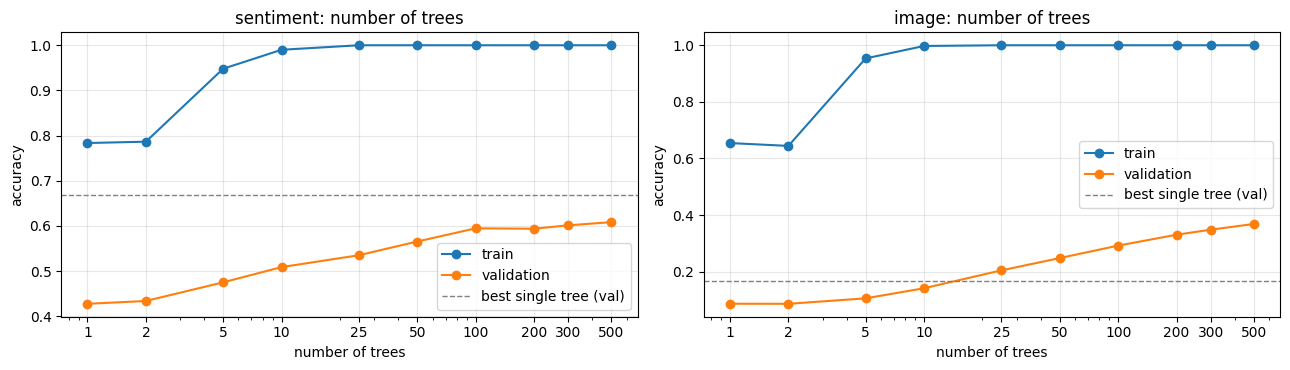

In [3]:
results = []
TREE_COUNTS = [1, 2, 5, 10, 25, 50, 100, 200, 300, 500]
CHECK = {t: np.random.default_rng(0).choice(len(SPLIT[t][0]), 2000, replace=False) for t in TASKS}   # train rows used for train accuracy

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, task in zip(axes, TASKS):
    X_tr, y_tr, X_va, y_va = SPLIT[task]
    start = time.time()
    forest = trees.RandomForest(n_trees=500).fit(X_tr, y_tr, N_CLASSES[task])
    fit_s = time.time() - start
    c = CHECK[task]
    tr_acc = [common.accuracy(y_tr[c], forest.predict(X_tr[c], n)) for n in TREE_COUNTS]
    va_acc = [common.accuracy(y_va, forest.predict(X_va, n)) for n in TREE_COUNTS]
    for n, a, b in zip(TREE_COUNTS, tr_acc, va_acc):
        results.append({"task": task, "experiment": "n_trees", "features": "raw", "n_trees": n, "max_features": "sqrt",
                        "max_depth": None, "min_samples_leaf": 1, "criterion": "gini", "bootstrap_fraction": 1.0,
                        "voting": "soft", "train_acc": round(a, 4), "val_acc": round(b, 4)})
    print(f"{task}: 500 trees in {fit_s:.0f}s | validation {va_acc[-1]:.4f} | out-of-bag {forest.oob_accuracy(X_tr, y_tr):.4f}")
    print("   " + "  ".join(f"{n}:{a:.3f}" for n, a in zip(TREE_COUNTS, va_acc)))
    ax.plot(TREE_COUNTS, tr_acc, marker="o", label="train")
    ax.plot(TREE_COUNTS, va_acc, marker="o", label="validation")
    ax.axhline(dt_best[task]["val_acc"], color="grey", ls="--", lw=1, label="best single tree (val)")
    ax.set_xscale("log"); ax.set_xticks(TREE_COUNTS); ax.set_xticklabels(TREE_COUNTS)
    ax.set_xlabel("number of trees"); ax.set_ylabel("accuracy"); ax.set_title(f"{task}: number of trees")
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.savefig("report/figures/rf_n_trees.png", dpi=150); plt.show()

Train accuracy is ≈1.0 from a few trees on, while validation keeps rising and then flattens:
more trees reduce variance and never over-fit; they only cost time.

## 4. Other hyper-parameters (200 trees each)

In [4]:
def run(task, experiment, features="raw", data=None, n_trees=200, **settings):
    """Train one forest and record train/validation accuracy and time."""
    X_tr, y_tr, X_va, y_va = data if data is not None else SPLIT[task]
    start = time.time()
    forest = trees.RandomForest(n_trees=n_trees, **settings).fit(X_tr, y_tr, N_CLASSES[task])
    fit_s = time.time() - start
    c = CHECK[task]
    row = {"task": task, "experiment": experiment, "features": features, "n_trees": n_trees,
           "max_features": str(settings.get("max_features", "sqrt")), "max_depth": settings.get("max_depth"),
           "min_samples_leaf": settings.get("min_samples_leaf", 1), "criterion": settings.get("criterion", "gini"),
           "bootstrap_fraction": settings.get("bootstrap_fraction", 1.0), "voting": settings.get("voting", "soft"),
           "train_acc": round(common.accuracy(y_tr[c], forest.predict(X_tr[c])), 4),
           "val_acc": round(common.accuracy(y_va, forest.predict(X_va)), 4), "seconds": round(fit_s, 1)}
    results.append(row)
    print(f"{task:<9} {experiment:<18} {features:<10} {str(settings):<45} train {row['train_acc']:.3f}  "
          f"validation {row['val_acc']:.4f}  ({fit_s:.0f}s)", flush=True)
    return row

### 4.1 Features per split (`max_features`)

Fewer features → more diverse trees (better averaging) but weaker trees. √500 ≈ 22 (image), √768 ≈ 27 (sentiment).

In [5]:
MF = {"sentiment": [3, 9, "sqrt", 60, 150], "image": [3, 5, 10, "sqrt", 50, 100]}
mf_rows = {t: [run(t, "max_features", max_features=m) for m in MF[t]] for t in TASKS}

sentiment max_features       raw        {'max_features': 3}                           train 1.000  validation 0.5750  (3s)


sentiment max_features       raw        {'max_features': 9}                           train 1.000  validation 0.5929  (3s)


sentiment max_features       raw        {'max_features': 'sqrt'}                      train 1.000  validation 0.5938  (5s)


sentiment max_features       raw        {'max_features': 60}                          train 1.000  validation 0.5954  (7s)


sentiment max_features       raw        {'max_features': 150}                         train 1.000  validation 0.5988  (13s)


image     max_features       raw        {'max_features': 3}                           train 1.000  validation 0.3125  (11s)


image     max_features       raw        {'max_features': 5}                           train 1.000  validation 0.3290  (16s)


image     max_features       raw        {'max_features': 10}                          train 1.000  validation 0.3300  (26s)


image     max_features       raw        {'max_features': 'sqrt'}                      train 1.000  validation 0.3307  (52s)


image     max_features       raw        {'max_features': 50}                          train 1.000  validation 0.3255  (119s)


image     max_features       raw        {'max_features': 100}                         train 1.000  validation 0.3113  (252s)


### 4.2 Tree size: `max_depth` and `min_samples_leaf`

In [6]:
def best_mf(task):
    m = max(mf_rows[task], key=lambda r: r["val_acc"])["max_features"]
    return m if m in ("sqrt", "log2") else int(m)


for task in TASKS:
    for d in [5, 10, 20, None]:
        run(task, "max_depth", max_features=best_mf(task), max_depth=d)
    for l in [2, 5, 10]:
        run(task, "min_samples_leaf", max_features=best_mf(task), min_samples_leaf=l)

sentiment max_depth          raw        {'max_features': 150, 'max_depth': 5}         train 0.650  validation 0.5617  (2s)


sentiment max_depth          raw        {'max_features': 150, 'max_depth': 10}        train 0.985  validation 0.5896  (7s)


sentiment max_depth          raw        {'max_features': 150, 'max_depth': 20}        train 1.000  validation 0.5908  (14s)


sentiment max_depth          raw        {'max_features': 150, 'max_depth': None}      train 1.000  validation 0.5988  (14s)


sentiment min_samples_leaf   raw        {'max_features': 150, 'min_samples_leaf': 2}  train 1.000  validation 0.5983  (13s)


sentiment min_samples_leaf   raw        {'max_features': 150, 'min_samples_leaf': 5}  train 0.999  validation 0.6062  (11s)


... (4 outputs left out)

image     max_depth          raw        {'max_features': 'sqrt', 'max_depth': None}   train 1.000  validation 0.3307  (58s)


image     min_samples_leaf   raw        {'max_features': 'sqrt', 'min_samples_leaf': 2} train 1.000  validation 0.3350  (44s)


image     min_samples_leaf   raw        {'max_features': 'sqrt', 'min_samples_leaf': 5} train 0.999  validation 0.3210  (20s)


image     min_samples_leaf   raw        {'max_features': 'sqrt', 'min_samples_leaf': 10} train 0.988  validation 0.2885  (10s)


### 4.3 Criterion, bootstrap size and voting

In [7]:
for task in TASKS:
    mf = best_mf(task)
    run(task, "criterion", max_features=mf, criterion="entropy")
    for b in [0.25, 0.5]:
        run(task, "bootstrap_fraction", max_features=mf, bootstrap_fraction=b)
    run(task, "voting", max_features=mf, voting="hard")

sentiment criterion          raw        {'max_features': 150, 'criterion': 'entropy'} train 1.000  validation 0.6071  (15s)


sentiment bootstrap_fraction raw        {'max_features': 150, 'bootstrap_fraction': 0.25} train 0.951  validation 0.5983  (5s)


sentiment bootstrap_fraction raw        {'max_features': 150, 'bootstrap_fraction': 0.5} train 0.999  validation 0.5967  (8s)


sentiment voting             raw        {'max_features': 150, 'voting': 'hard'}       train 1.000  validation 0.5988  (14s)


image     criterion          raw        {'max_features': 'sqrt', 'criterion': 'entropy'} train 1.000  validation 0.3137  (115s)


image     bootstrap_fraction raw        {'max_features': 'sqrt', 'bootstrap_fraction': 0.25} train 0.999  validation 0.2690  (19s)


image     bootstrap_fraction raw        {'max_features': 'sqrt', 'bootstrap_fraction': 0.5} train 1.000  validation 0.2985  (34s)


image     voting             raw        {'max_features': 'sqrt', 'voting': 'hard'}    train 1.000  validation 0.3302  (56s)


### 4.4 Raw features, LDA projection, or both

Same LDA as `decision_tree.ipynb`, fitted on the training rows only.

In [8]:
def lda_versions(task, shrinkage):
    X_tr, y_tr, X_va, y_va = SPLIT[task]
    lda = trees.fit_lda(X_tr, y_tr, N_CLASSES[task], shrinkage)
    A_tr, A_va = trees.apply_lda(X_tr, lda), trees.apply_lda(X_va, lda)
    return {"lda": (A_tr, y_tr, A_va, y_va),
            "raw+lda": (np.hstack([X_tr, A_tr]), y_tr, np.hstack([X_va, A_va]), y_va)}


for task in TASKS:
    for s in [0.1, 0.3, 0.5]:
        for name, data in lda_versions(task, s).items():
            mf = "sqrt" if name == "raw+lda" else (1 if task == "sentiment" else 7)   # ~sqrt of the LDA dimensions
            for leaf in ([1, 20] if name == "lda" else [1]):
                run(task, "representation", features=f"{name} s={s}", data=data, max_features=mf, min_samples_leaf=leaf)

sentiment representation     lda s=0.1  {'max_features': 1, 'min_samples_leaf': 1}    train 0.794  validation 0.6475  (1s)


sentiment representation     lda s=0.1  {'max_features': 1, 'min_samples_leaf': 20}   train 0.745  validation 0.6692  (1s)


sentiment representation     raw+lda s=0.1 {'max_features': 'sqrt', 'min_samples_leaf': 1} train 1.000  validation 0.6617  (5s)


sentiment representation     lda s=0.3  {'max_features': 1, 'min_samples_leaf': 1}    train 0.781  validation 0.6450  (1s)


sentiment representation     lda s=0.3  {'max_features': 1, 'min_samples_leaf': 20}   train 0.731  validation 0.6667  (1s)


sentiment representation     raw+lda s=0.3 {'max_features': 'sqrt', 'min_samples_leaf': 1} train 1.000  validation 0.6604  (5s)


... (8 outputs left out)

image     representation     raw+lda s=0.3 {'max_features': 'sqrt', 'min_samples_leaf': 1} train 1.000  validation 0.3043  (55s)


image     representation     lda s=0.5  {'max_features': 7, 'min_samples_leaf': 1}    train 1.000  validation 0.2883  (17s)


image     representation     lda s=0.5  {'max_features': 7, 'min_samples_leaf': 20}   train 0.871  validation 0.2767  (3s)


image     representation     raw+lda s=0.5 {'max_features': 'sqrt', 'min_samples_leaf': 1} train 1.000  validation 0.3137  (54s)


## 5. Selected forest per task (best validation accuracy, retrained with 500 trees)

In [9]:
table = pd.DataFrame(results)
for task in TASKS:
    table[table.task == task].sort_values("val_acc", ascending=False).to_csv(
        f"random_forest/outputs/{task}_experiments.csv", index=False)

best = {task: max([r for r in results if r["task"] == task and r["experiment"] != "n_trees"],
                  key=lambda r: r["val_acc"]) for task in TASKS}
display(pd.DataFrame([best[t] for t in TASKS]))

FINAL_TREES = 500


def settings_of(row):
    mf = row["max_features"]
    return dict(max_features=mf if mf in ("sqrt", "log2") else int(mf),
                max_depth=None if row["max_depth"] is None or pd.isna(row["max_depth"]) else int(row["max_depth"]),
                min_samples_leaf=int(row["min_samples_leaf"]), criterion=row["criterion"],
                bootstrap_fraction=float(row["bootstrap_fraction"]), voting=row["voting"])


def transform_for(row, X_fit, y_fit, n_classes, *others):
    """Apply the selected features: LDA is fitted on X_fit only."""
    if row["features"] == "raw":
        return (X_fit,) + others
    name, s = row["features"].split(" s=")
    lda = trees.fit_lda(X_fit, y_fit, n_classes, float(s))
    return tuple(trees.apply_lda(M, lda) if name == "lda" else np.hstack([M, trees.apply_lda(M, lda)])
                 for M in (X_fit,) + others)


final_forests, val_pred, val_proba = {}, {}, {}
for task in TASKS:
    row = best[task]
    X_tr, y_tr, X_va, y_va = SPLIT[task]
    A_tr, A_va = transform_for(row, X_tr, y_tr, N_CLASSES[task], X_va)
    start = time.time()
    forest = trees.RandomForest(n_trees=FINAL_TREES, **settings_of(row)).fit(A_tr, y_tr, N_CLASSES[task])
    fit_s = time.time() - start
    val_proba[task] = forest.predict_proba(A_va)
    val_pred[task] = val_proba[task].argmax(1)
    final_forests[task] = (forest, A_tr, A_va)
    np.save(f"random_forest/outputs/{task}_val_pred.npy", val_pred[task])       # read by final/compare.ipynb
    np.save(f"random_forest/outputs/{task}_val_proba.npy", val_proba[task])     # read by final/ensemble.ipynb
    print(f"{task}: {row['features']} {settings_of(row)}")
    print(f"   {FINAL_TREES} trees: validation {common.accuracy(y_va, val_pred[task]):.4f}   "
          f"OOB {forest.oob_accuracy(A_tr, y_tr):.4f}   train {fit_s:.0f}s")

,task,experiment,features,n_trees,max_features,max_depth,min_samples_leaf,criterion,bootstrap_fraction,voting,train_acc,val_acc,seconds
0,sentiment,representation,lda s=0.1,200,1,None,20,gini,1.0,soft,0.745,0.6692,0.9
1,image,min_samples_leaf,raw,200,sqrt,None,2,gini,1.0,soft,1.000,0.3350,43.8


sentiment: lda s=0.1 {'max_features': 1, 'max_depth': None, 'min_samples_leaf': 20, 'criterion': 'gini', 'bootstrap_fraction': 1.0, 'voting': 'soft'}


   500 trees: validation 0.6708   OOB 0.7241   train 1s


image: raw {'max_features': 'sqrt', 'max_depth': None, 'min_samples_leaf': 2, 'criterion': 'gini', 'bootstrap_fraction': 1.0, 'voting': 'soft'}


   500 trees: validation 0.3685   OOB 0.3292   train 102s


## 6. Random Forest vs a single Decision Tree

`gap` = train − validation accuracy. "One fully grown tree" uses the same features as the forest.

,task,model,features,train_acc,val_acc,gap
0,sentiment,best single Decision Tree,lda s=0.3,0.7252,0.6692,0.0560
1,sentiment,one fully grown tree,lda s=0.1,0.8145,0.6112,0.2032
2,sentiment,Random Forest (500 trees),lda s=0.1,0.7440,0.6708,0.0732
3,image,best single Decision Tree,lda s=0.5,0.3412,0.1678,0.1734
4,image,one fully grown tree,raw,1.0000,0.1258,0.8742
5,image,Random Forest (500 trees),raw,1.0000,0.3685,0.6315


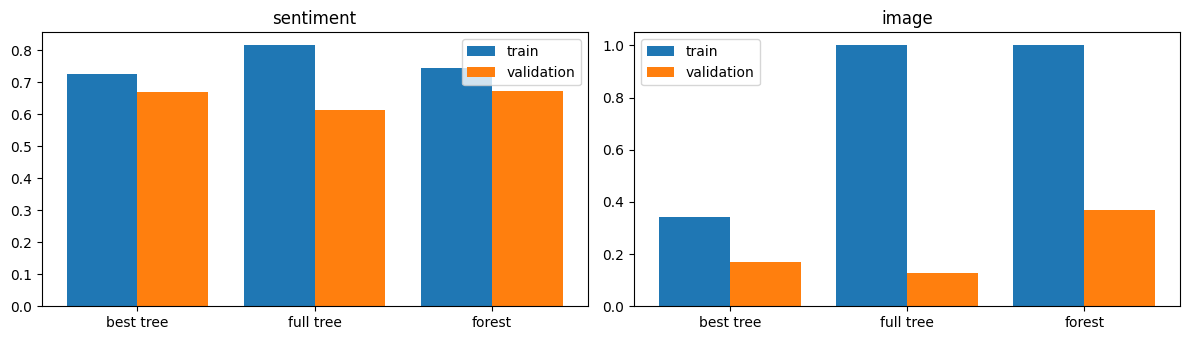

sentiment both right  1492 | only forest   118 | only tree   114 | both wrong   676
image     both right   495 | only forest   979 | only tree   176 | both wrong  2350


In [10]:
rows = []
for task in TASKS:
    X_tr, y_tr, X_va, y_va = SPLIT[task]
    forest, A_tr, A_va = final_forests[task]
    c = CHECK[task]
    one = trees.DecisionTree().fit(A_tr, y_tr, N_CLASSES[task])
    rows += [{"task": task, "model": "best single Decision Tree", "features": dt_best[task]["features"],
              "train_acc": dt_best[task]["train_acc"], "val_acc": dt_best[task]["val_acc"]},
             {"task": task, "model": "one fully grown tree", "features": best[task]["features"],
              "train_acc": common.accuracy(y_tr, one.predict(A_tr)), "val_acc": common.accuracy(y_va, one.predict(A_va))},
             {"task": task, "model": f"Random Forest ({FINAL_TREES} trees)", "features": best[task]["features"],
              "train_acc": common.accuracy(y_tr[c], forest.predict(A_tr[c])), "val_acc": common.accuracy(y_va, val_pred[task])}]
cmp = pd.DataFrame(rows)
cmp["gap"] = cmp["train_acc"] - cmp["val_acc"]
display(cmp.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))      # train vs validation per model
for ax, task in zip(axes, TASKS):
    part = cmp[cmp.task == task]
    x = np.arange(len(part))
    ax.bar(x - 0.2, part.train_acc, 0.4, label="train"); ax.bar(x + 0.2, part.val_acc, 0.4, label="validation")
    ax.set_xticks(x); ax.set_xticklabels(["best tree", "full tree", "forest"]); ax.set_title(task); ax.legend()
plt.tight_layout(); plt.savefig("report/figures/rf_vs_tree.png", dpi=150); plt.show()

for task in TASKS:      # which validation rows each model gets right
    y_va = SPLIT[task][3]
    dt_ok = np.load(f"decision_tree/outputs/{task}_val_pred.npy") == y_va
    rf_ok = val_pred[task] == y_va
    print(f"{task:<9} both right {np.sum(dt_ok & rf_ok):5d} | only forest {np.sum(~dt_ok & rf_ok):5d} | "
          f"only tree {np.sum(dt_ok & ~rf_ok):5d} | both wrong {np.sum(~dt_ok & ~rf_ok):5d}")

## 7. Error analysis

In [11]:
def per_class_table(y_true, y_pred, n_classes, names=None):
    cm = common.confusion_matrix(y_true, y_pred, n_classes)
    p, r = common.per_class_precision(cm), common.per_class_recall(cm)
    f1 = np.where(p + r > 0, 2 * p * r / np.maximum(p + r, 1e-12), 0)
    return cm, pd.DataFrame({"precision": p, "recall": r, "f1": f1}, index=names or range(n_classes)).round(3)


y_va = SPLIT["sentiment"][3]
cm, per_class = per_class_table(y_va, val_pred["sentiment"], 3, common.SENTIMENT_NAMES)
print("Sentiment confusion matrix (rows = true, columns = predicted)")
display(pd.DataFrame(cm, index=common.SENTIMENT_NAMES, columns=common.SENTIMENT_NAMES))
display(per_class)

y_va = SPLIT["image"][3]
cm, per_class = per_class_table(y_va, val_pred["image"], 50)
print("Image: 5 hardest and 5 easiest classes (by recall)")
display(pd.concat([per_class.sort_values("recall").head(5), per_class.sort_values("recall").tail(5)]))
print("Most frequent confusions (true -> predicted, out of 80):")
for t, p, n in common.most_confused_pairs(cm, 8):
    print(f"   {t:2d} -> {p:2d}   {n}")

Sentiment confusion matrix (rows = true, columns = predicted)


,Negative,Neutral,Positive
Negative,619,128,53
Neutral,175,451,174
Positive,93,167,540


,precision,recall,f1
Negative,0.698,0.774,0.734
Neutral,0.605,0.564,0.583
Positive,0.704,0.675,0.689


Image: 5 hardest and 5 easiest classes (by recall)


,precision,recall,f1
22,0.387,0.150,0.216
29,0.462,0.150,0.226
21,0.333,0.162,0.218
6,0.245,0.162,0.195
40,0.206,0.162,0.182
13,0.417,0.662,0.512
25,0.317,0.662,0.429
46,0.342,0.662,0.451
5,0.450,0.675,0.540
48,0.495,0.688,0.576


Most frequent confusions (true -> predicted, out of 80):
    4 ->  2   20
    3 ->  2   19
   27 -> 25   11
   10 -> 12   10
   34 -> 32   10
    7 ->  8   9
   37 -> 39   9
    1 ->  2   8


In [12]:
for task in TASKS:      # is the forest's confidence meaningful?
    y_va = SPLIT[task][3]
    conf, ok = val_proba[task].max(1), val_pred[task] == y_va
    print(f"{task}: mean top probability when right {conf[ok].mean():.3f}, when wrong {conf[~ok].mean():.3f}")
    edges = np.quantile(conf, [0, .25, .5, .75, 1])
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf >= lo) & (conf <= hi)
        print(f"      confidence {lo:.2f}-{hi:.2f}: accuracy {ok[m].mean():.3f}")

sentiment: mean top probability when right 0.758, when wrong 0.658
      confidence 0.35-0.60: accuracy 0.500
      confidence 0.60-0.73: accuracy 0.607
      confidence 0.73-0.87: accuracy 0.723
      confidence 0.87-0.99: accuracy 0.852
image: mean top probability when right 0.151, when wrong 0.068
      confidence 0.03-0.05: accuracy 0.141
      confidence 0.05-0.06: accuracy 0.284
      confidence 0.06-0.10: accuracy 0.392
      confidence 0.10-0.87: accuracy 0.657


### Feature importance

Impurity importance (what the trees used while training) and permutation importance from Lab 5
(accuracy drop on validation when a feature is shuffled; for image, the 20 features with the highest impurity importance).

sentiment: 1 of 2 features hold half of the impurity importance


   permutation (accuracy drop): 0: +0.2460, 1: +0.1247


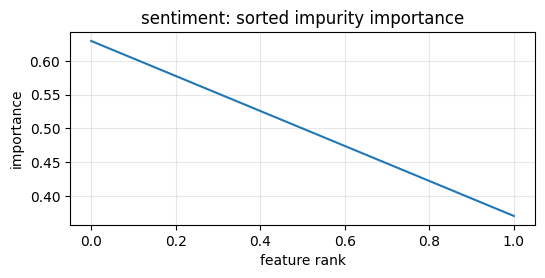

image: 190 of 500 features hold half of the impurity importance


   permutation (accuracy drop): 348: +0.0193, 196: +0.0153, 39: +0.0130, 230: +0.0114, 119: +0.0090, 319: +0.0075, 422: +0.0066, 405: +0.0057, 152: +0.0053, 27: +0.0048


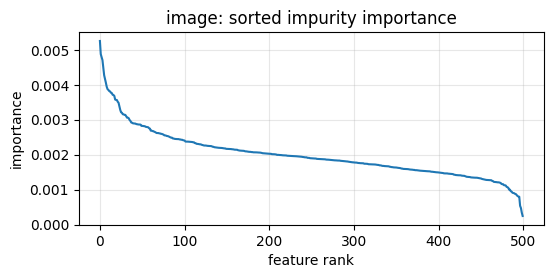

In [13]:
for task in TASKS:
    forest, A_tr, A_va = final_forests[task]
    imp = np.mean([t.feature_importance(A_tr.shape[1]) for t in forest.trees], axis=0)
    k = int(np.searchsorted(np.cumsum(np.sort(imp)[::-1]), 0.5)) + 1
    print(f"{task}: {k} of {A_tr.shape[1]} features hold half of the impurity importance")
    feats, drops = trees.permutation_importance(forest, A_va, SPLIT[task][3], np.argsort(imp)[::-1][:20])
    order = np.argsort(drops)[::-1][:10]
    print("   permutation (accuracy drop):", ", ".join(f"{feats[i]}: {drops[i]:+.4f}" for i in order))
    plt.figure(figsize=(6, 2.5)); plt.plot(np.sort(imp)[::-1]); plt.title(f"{task}: sorted impurity importance")
    plt.xlabel("feature rank"); plt.ylabel("importance"); plt.grid(alpha=0.3); plt.show()

## 8. Test predictions for Kaggle

Selected settings, 500 trees, retrained on all training rows (LDA refitted on all training rows if used).

In [14]:
for task in TASKS:
    row = best[task]
    X, y = DATA[task]
    X_test, test_ids = TEST[task]
    A, A_test = transform_for(row, X, y, N_CLASSES[task], X_test)
    start = time.time()
    forest = trees.RandomForest(n_trees=FINAL_TREES, **settings_of(row)).fit(A, y, N_CLASSES[task])
    proba = forest.predict_proba(A_test)
    np.save(f"random_forest/outputs/{task}_test_proba.npy", proba)             # read by final/ensemble.ipynb
    pd.DataFrame({"id": test_ids, "label": proba.argmax(1)}).to_csv(f"random_forest/outputs/{task}_test_pred.csv", index=False)
    print(f"{task}: saved random_forest/outputs/{task}_test_pred.csv  ({time.time() - start:.0f}s)")

sentiment: saved random_forest/outputs/sentiment_test_pred.csv  (1s)


image: saved random_forest/outputs/image_test_pred.csv  (122s)


## 9. Findings

* **Forest vs tree (raw features):** image 0.126 → 0.369, sentiment 0.428 → 0.608. Train stays 1.0, so the gain is lower
  variance, not lower bias.
* **Number of trees:** image validation 0.087 (1 tree) → 0.248 (50) → 0.369 (500), still rising slowly; more trees never hurt.
* **max_features:** image is best with few features per split (5–22: 0.329–0.331, 100: 0.311); raw sentiment prefers more (150: 0.599).
* **Limits hurt a forest:** image depth 10 gives 0.190 vs 0.331 unlimited; min_samples_leaf 10 gives 0.289; 25% bootstrap 0.269.
  Soft ≈ hard voting; entropy is worse on image.
* **Sentiment with LDA:** forest 0.671 vs best single tree 0.669; with 2 input features there is little room for diversity.
  OOB (0.724) is optimistic here because LDA was fitted on the same training rows.
* **Errors:** Neutral sentiment is hardest (recall 0.56). Image classes 3 and 4 are most often predicted as 2.
  High-confidence predictions are much more accurate (sentiment 85% vs 50% for the lowest quarter).